# Main Evaluation Report: The Sharpness Quest

## Setup and Imports

In [1]:
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import os
import cv2
import scipy.linalg

from models import cVAE, SimpleClassifier

# Fix random seeds for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

# Ensure deterministic GPU operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# Define parameters
z_dim = 7
num_classes = 10
batch_size = 1000

# Use GPU when available; otherwise use CPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Create directory for evaluation outputs
os.makedirs('assets', exist_ok=True)

Using device: cuda:0


## 1. Load the Custom MNIST Dataset

The provided `mnist_custom.pt` dataset is loaded for model evaluation. The original test set is kept separate from the training and validation data and is used for the final comparison of the baseline and modified cVAE.

In [2]:
# Load the provided custom MNIST dataset
data_custom = torch.load('mnist_custom.pt', weights_only=False)

# Create the test dataset for final model evaluation
test_dataset = TensorDataset(data_custom['test_images'], data_custom['test_labels'])
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

# Check the test data
print(f"Test samples: {len(test_dataset)}")
print(f"Test image shape: {data_custom['test_images'].shape}")

Test samples: 10000
Test image shape: torch.Size([10000, 1, 20, 20])


## Dataset Inspection

A quick visual check of the test data to confirm the 20×20 pixel format and class label correctness.

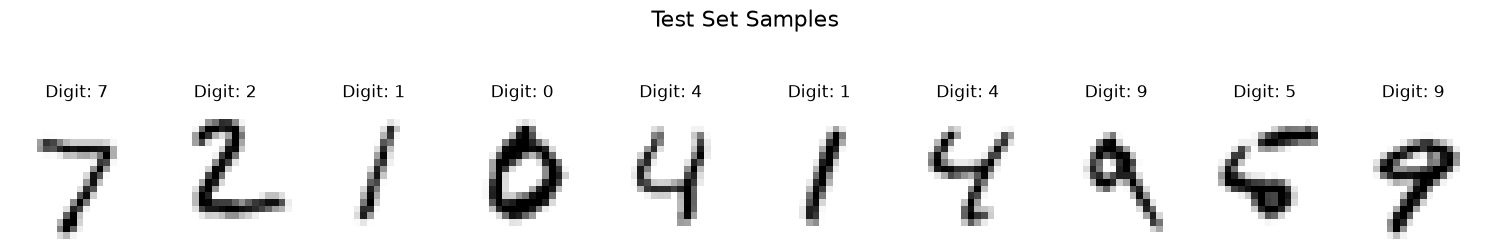

In [3]:
# Examine some samples from the custom dataset to understand the data distribution
batch_x, batch_y = next(iter(test_dataloader))
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for i in range(10):
    axes[i].imshow(batch_x[i].squeeze(), cmap='gray')
    axes[i].set_title(f'Digit: {batch_y[i].item()}', fontsize=12)
    axes[i].axis('off')
plt.suptitle('Test Set Samples', fontsize=16)
plt.tight_layout()
plt.show()

## 2. Load the Trained cVAE Models

The final baseline and modified cVAE models are loaded using the weights obtained after retraining on the full training dataset. Both models use the same architecture and seven-dimensional latent space, with the modified model differing only in the training objective through the additional discriminator-based loss.

In [4]:
# Initialise the baseline and modified cVAE models
base_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)
modified_vae = cVAE(z_dim=z_dim, num_classes=num_classes).to(device)

# Load the final model weights
base_vae.load_state_dict(torch.load('assets/base_vae_weights.pt', map_location=device, weights_only=True))
modified_vae.load_state_dict(torch.load('assets/modified_vae_weights.pt', map_location=device, weights_only=True))

# Set both models to evaluation mode
base_vae.eval()
modified_vae.eval()

print("Baseline and modified cVAE models loaded successfully.")

Baseline and modified cVAE models loaded successfully.


## 3. Conditional Generation

To qualitatively compare the two cVAE variants, conditional sampling is performed for all 10 digit classes. For each digit class, 12 images are generated, resulting in 120 generated images per model.

The same latent vectors are used for both models to ensure a direct comparison between the baseline and modified cVAE. The generated images are compared in terms of visual quality, sharpness, consistency, and variety.

### Visual Comparison of Generated Digits

The generated samples from the baseline and modified cVAE are shown below. Each row represents one digit class from 0 to 9, with 12 conditionally generated samples per class. The same latent vectors are used by both models, allowing their outputs to be compared directly.

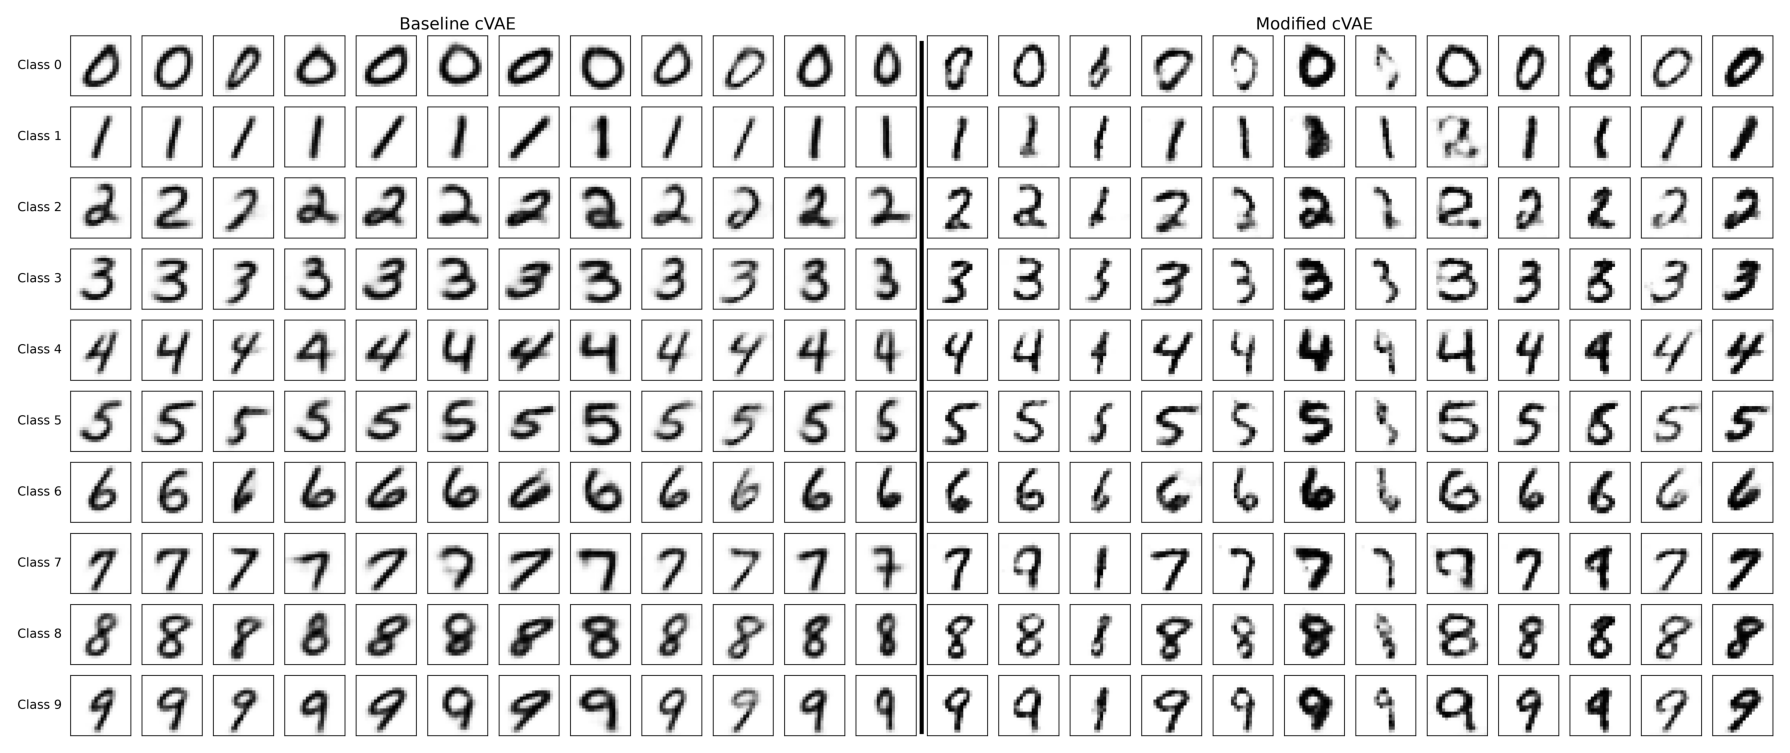

In [5]:
# Load and display the conditional generation comparison
img = plt.imread('assets/conditional_generation_comparison.png')

plt.figure(figsize=(18, 9))
plt.imshow(img)
plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Quantitative Evaluation

### Image Sharpness (Laplacian Variance)

Laplacian variance is used to quantify the sharpness of the conditionally generated images. The Laplacian operator measures local intensity changes and edge information within an image, and the variance of the resulting response provides an indication of high-frequency detail.

A higher Laplacian variance generally indicates stronger edge detail and greater image sharpness. However, this metric can also respond to noise or artefacts, so the results are interpreted together with the visual comparison.

### Interpretation

- **Higher Laplacian variance** → Stronger edge detail and potentially sharper images
- **Lower Laplacian variance** → Smoother or blurrier images
- **Important:** A higher score does not necessarily mean better image quality, as noise and artefacts can also increase Laplacian variance

In [6]:
# Reset the random seed for reproducible sampling
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# Generate 12 shared latent samples
num_samples = 12
z_samples = torch.randn(num_samples, z_dim).to(device)

base_generated = []
modified_generated = []

with torch.no_grad():
    for digit in range(num_classes):
        labels = torch.full((num_samples,), digit, device=device)
        cond = F.one_hot(labels, num_classes=num_classes).float()

        # Generate samples using the same latent vectors
        base_samples = base_vae.decode(z_samples, cond)
        modified_samples = modified_vae.decode(z_samples, cond)

        base_generated.append(base_samples.cpu())
        modified_generated.append(modified_samples.cpu())

base_generated = torch.cat(base_generated, dim=0)
modified_generated = torch.cat(modified_generated, dim=0)

print(f"Baseline generated images: {base_generated.shape}")
print(f"Modified generated images: {modified_generated.shape}")

Baseline generated images: torch.Size([120, 1, 20, 20])
Modified generated images: torch.Size([120, 1, 20, 20])


In [7]:
# Calculate Laplacian variance for generated images
def compute_laplacian_variance(images):
    images_np = images.view(-1, 20, 20).cpu().numpy()
    return np.array([
        cv2.Laplacian(img, cv2.CV_32F).var()
        for img in images_np
    ])

base_sharpness = compute_laplacian_variance(base_generated)
modified_sharpness = compute_laplacian_variance(modified_generated)

print(f'Baseline Sharpness: {base_sharpness.mean():.2f}')
print(f'Modified Sharpness: {modified_sharpness.mean():.2f}')

Baseline Sharpness: 0.09
Modified Sharpness: 0.18


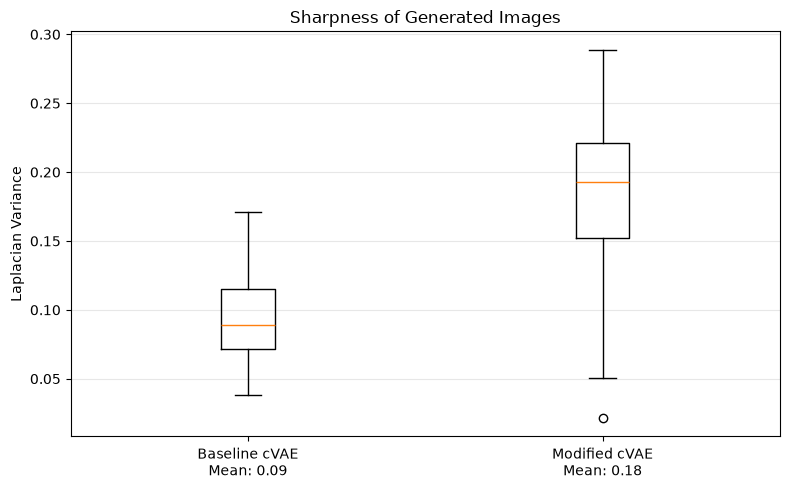

In [8]:
# Plot the distribution of Laplacian variance
plt.figure(figsize=(8, 5))

plt.boxplot(
    [base_sharpness, modified_sharpness],
    tick_labels=[
        f'Baseline cVAE\nMean: {base_sharpness.mean():.2f}',
        f'Modified cVAE\nMean: {modified_sharpness.mean():.2f}'
    ]
)

plt.ylabel('Laplacian Variance')
plt.title('Sharpness of Generated Images')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('assets/laplacian_variance_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Generated Digit Recognisability (Standalone Digit Classifier to Measure)

A standalone digit classifier is trained using only real images from the custom MNIST training set. The classifier is not exposed to images generated by either cVAE during training, providing an independent evaluation of how readily the generated digits can be recognised.

Before evaluating the generated images, the classifier is evaluated on the held-out real test set to verify its recognition performance on real digits.

The trained classifier is then used to classify conditionally generated images from both cVAE variants. The predicted classes are compared with their conditioning labels to calculate classification accuracy.

### Interpretation

- **Higher accuracy** → Generated digits more consistently match their intended conditioning class
- **Lower accuracy** → Generated digits are more ambiguous or inconsistent with their intended class
- This metric complements Laplacian variance by determining whether increased sharpness is accompanied by clearly recognisable digit structures

In [9]:
# Create a training dataset using only real images
classifier_train_dataset = TensorDataset(data_custom['train_images'], data_custom['train_labels'])
classifier_train_dataloader = DataLoader(classifier_train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

# Reset the random seed before classifier initialisation
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

# Initialise the standalone classifier
classifier = SimpleClassifier().to(device)
optimizer_classifier = torch.optim.Adam(classifier.parameters(), lr=0.001)
criterion_classifier = torch.nn.CrossEntropyLoss()
classifier_epochs = 10

In [10]:
# Train the standalone classifier using real images only
classifier.train()

for epoch in range(classifier_epochs):
    train_loss = 0.0
    correct = 0
    total = 0

    for images, labels in classifier_train_dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = classifier(images)
        loss = criterion_classifier(outputs, labels)

        optimizer_classifier.zero_grad()
        loss.backward()
        optimizer_classifier.step()

        train_loss += loss.item()
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss /= len(classifier_train_dataloader)
    train_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch + 1}/{classifier_epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )

Epoch 1/10 | Loss: 1.4837 | Accuracy: 58.50%
Epoch 2/10 | Loss: 0.4614 | Accuracy: 86.18%
Epoch 3/10 | Loss: 0.3589 | Accuracy: 89.24%
Epoch 4/10 | Loss: 0.3127 | Accuracy: 90.69%
Epoch 5/10 | Loss: 0.2792 | Accuracy: 91.70%
Epoch 6/10 | Loss: 0.2458 | Accuracy: 92.76%
Epoch 7/10 | Loss: 0.2150 | Accuracy: 93.61%
Epoch 8/10 | Loss: 0.1870 | Accuracy: 94.43%
Epoch 9/10 | Loss: 0.1626 | Accuracy: 95.10%
Epoch 10/10 | Loss: 0.1423 | Accuracy: 95.79%


#### Classifier Validation

Before evaluating the generated images, the standalone classifier is evaluated on the held-out real test set. This verifies that the classifier can reliably recognise real digits from the custom MNIST dataset.

In [11]:
# Evaluate the classifier on the real test set
classifier.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = classifier(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

classifier_test_accuracy = 100 * correct / total

print(f"Classifier test accuracy: {classifier_test_accuracy:.2f}%")

Classifier test accuracy: 96.23%


#### Generated Digit Recognition

The standalone classifier is used to evaluate whether the conditionally generated images are recognisable as their intended digit classes. For a more reliable quantitative evaluation, 1,000 images are generated from each cVAE, with 100 samples for each digit class.

The predicted classes are compared with the conditioning labels. A higher classification accuracy indicates that the generated digits more consistently preserve their intended class identity.

In [12]:
# Generate 100 samples for each digit class
samples_per_class = 100

base_recognition = []
modified_recognition = []
recognition_labels = []

# Reset the random seed for reproducible sampling
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

with torch.no_grad():
    for digit in range(num_classes):
        z = torch.randn(samples_per_class, z_dim).to(device)
        labels = torch.full((samples_per_class,), digit, device=device)
        cond = F.one_hot(labels, num_classes=num_classes).float()

        # Generate samples using the same latent vectors
        base_recognition.append(base_vae.decode(z, cond).cpu())
        modified_recognition.append(modified_vae.decode(z, cond).cpu())
        recognition_labels.append(labels.cpu())

base_recognition = torch.cat(base_recognition, dim=0)
modified_recognition = torch.cat(modified_recognition, dim=0)
recognition_labels = torch.cat(recognition_labels, dim=0)

print(f"Baseline generated images: {base_recognition.shape}")
print(f"Modified generated images: {modified_recognition.shape}")

Baseline generated images: torch.Size([1000, 1, 20, 20])
Modified generated images: torch.Size([1000, 1, 20, 20])


In [13]:
# Evaluate generated digit recognisability
def generated_accuracy(classifier, images, labels):
    classifier.eval()

    with torch.no_grad():
        outputs = classifier(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

    return 100 * (predictions == labels).float().mean().item()

base_classifier_accuracy = generated_accuracy(classifier, base_recognition, recognition_labels)
modified_classifier_accuracy = generated_accuracy(classifier, modified_recognition, recognition_labels)

print(f"Baseline generated digit accuracy: {base_classifier_accuracy:.2f}%")
print(f"Modified generated digit accuracy: {modified_classifier_accuracy:.2f}%")

Baseline generated digit accuracy: 98.90%
Modified generated digit accuracy: 92.90%


### Distribution Quality — Fréchet Classifier Distance (FCD)

Fréchet Classifier Distance (FCD) is used to evaluate how closely the generated image distribution matches the real digit distribution. It follows the principle of Fréchet Inception Distance (FID), but uses features extracted from the standalone digit classifier trained on the custom MNIST dataset rather than an ImageNet-based Inception network.

Features are extracted from the 10,000 real test images and 10,000 independently generated images from each cVAE. The distance between the real and generated feature distributions is calculated as:

$$
\mathrm{FCD} =
\|\mu_r-\mu_g\|_2^2 +
\mathrm{Tr}\left(
\Sigma_r+\Sigma_g
-2(\Sigma_r\Sigma_g)^{1/2}
\right)
$$

where $\mu_r$ and $\Sigma_r$ represent the mean and covariance of real-image features, while $\mu_g$ and $\Sigma_g$ represent those of generated-image features.

### Interpretation

- **Lower FCD** → Generated feature distribution is closer to the real digit distribution
- **Higher FCD** → Greater difference between the generated and real distributions
- Unlike Laplacian variance, FCD evaluates overall distribution similarity rather than image sharpness alone

In [14]:
# Extract classifier features from real images
def extract_real_features(dataloader, classifier):
    features = []
    classifier.eval()

    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            batch_features = classifier.extract_features(images)
            features.append(batch_features.cpu().numpy())

    return np.concatenate(features, axis=0)

# Extract classifier features from generated images
def extract_generated_features(model, classifier, n_samples=10000):
    features = []
    samples_per_batch = 100

    model.eval()
    classifier.eval()

    with torch.no_grad():
        for _ in range(n_samples // samples_per_batch):
            z = torch.randn(samples_per_batch, z_dim).to(device)
            labels = torch.randint(
                0,
                num_classes,
                (samples_per_batch,),
                device=device
            )
            cond = F.one_hot(labels, num_classes=num_classes).float()

            generated_images = model.decode(z, cond)
            batch_features = classifier.extract_features(generated_images)
            features.append(batch_features.cpu().numpy())

    return np.concatenate(features, axis=0)

In [15]:
# Extract features from real test images
real_features = extract_real_features(
    test_dataloader,
    classifier
)

# Reset the random seed to use identical sampling for both models
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

base_features = extract_generated_features(
    base_vae,
    classifier,
    n_samples=10000
)

# Reset the seed so the modified model uses the same latent vectors and labels
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

modified_features = extract_generated_features(
    modified_vae,
    classifier,
    n_samples=10000
)

print(f"Real features: {real_features.shape}")
print(f"Baseline features: {base_features.shape}")
print(f"Modified features: {modified_features.shape}")

Real features: (10000, 128)
Baseline features: (10000, 128)
Modified features: (10000, 128)


In [16]:
# Calculate Fréchet Classifier Distance
def calculate_fcd(real_features, generated_features, eps=1e-6):
    mu_real = np.mean(real_features, axis=0)
    mu_generated = np.mean(generated_features, axis=0)

    cov_real = np.cov(real_features, rowvar=False)
    cov_generated = np.cov(generated_features, rowvar=False)

    # Add a small value to the diagonal for numerical stability
    offset = np.eye(cov_real.shape[0]) * eps
    cov_real = cov_real + offset
    cov_generated = cov_generated + offset

    mean_difference = mu_real - mu_generated
    cov_mean = scipy.linalg.sqrtm(cov_real @ cov_generated)

    if np.iscomplexobj(cov_mean):
        cov_mean = cov_mean.real

    return (
        mean_difference @ mean_difference
        + np.trace(cov_real)
        + np.trace(cov_generated)
        - 2 * np.trace(cov_mean)
    )

# Calculate FCD for both models
base_fcd = calculate_fcd(real_features, base_features)
modified_fcd = calculate_fcd(real_features, modified_features)

print(f"Baseline FCD: {base_fcd:.4f}")
print(f"Modified FCD: {modified_fcd:.4f}")

Baseline FCD: 2.7895
Modified FCD: 5.3488


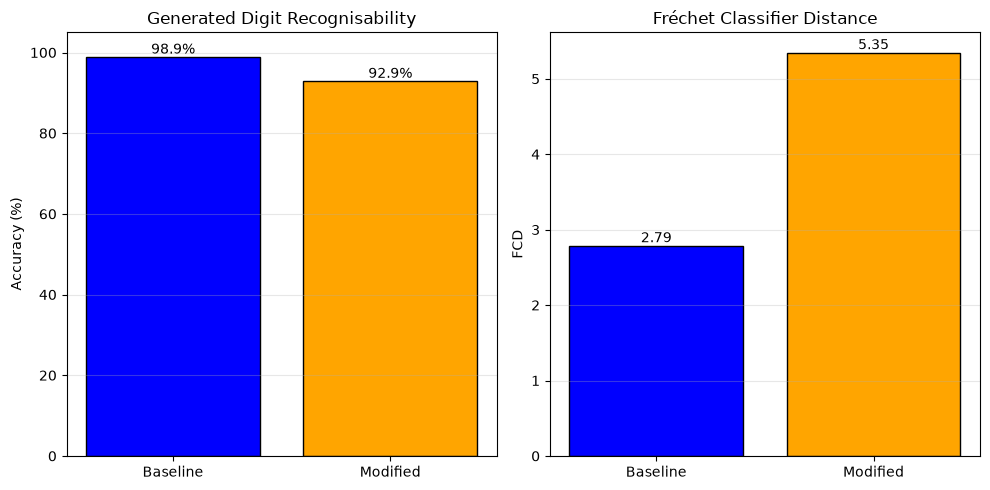

In [18]:
# Create the final quantitative evaluation figure
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Generated digit recognisability
recognition_bars = axes[0].bar(
    ['Baseline', 'Modified'],
    [base_classifier_accuracy, modified_classifier_accuracy],
    color=['blue', 'orange'],
    edgecolor='black'
)

axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Generated Digit Recognisability')
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', alpha=0.3)

for bar in recognition_bars:
    value = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.1f}%',
        ha='center',
        va='bottom'
    )

# Fréchet Classifier Distance
fcd_bars = axes[1].bar(
    ['Baseline', 'Modified'],
    [base_fcd, modified_fcd],
    color=['blue', 'orange'],
    edgecolor='black'
)

axes[1].set_ylabel('FCD')
axes[1].set_title('Fréchet Classifier Distance')
axes[1].grid(axis='y', alpha=0.3)

for bar in fcd_bars:
    value = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig('assets/final_evaluation_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Reconstruction Confusion Matrices

### Methodology
We pass real test images through each model's encoder→decoder pipeline, then classify the reconstructions with the standalone classifier. The confusion matrix reveals:
- **Diagonal dominance** → The model faithfully preserves digit identity during reconstruction
- **Off-diagonal entries** → Systematic confusions (e.g., 3s reconstructed as 8s)

### Interpretation
This tests whether the discriminator loss helps or hinders the model's ability to preserve semantic content during the encode-decode cycle.

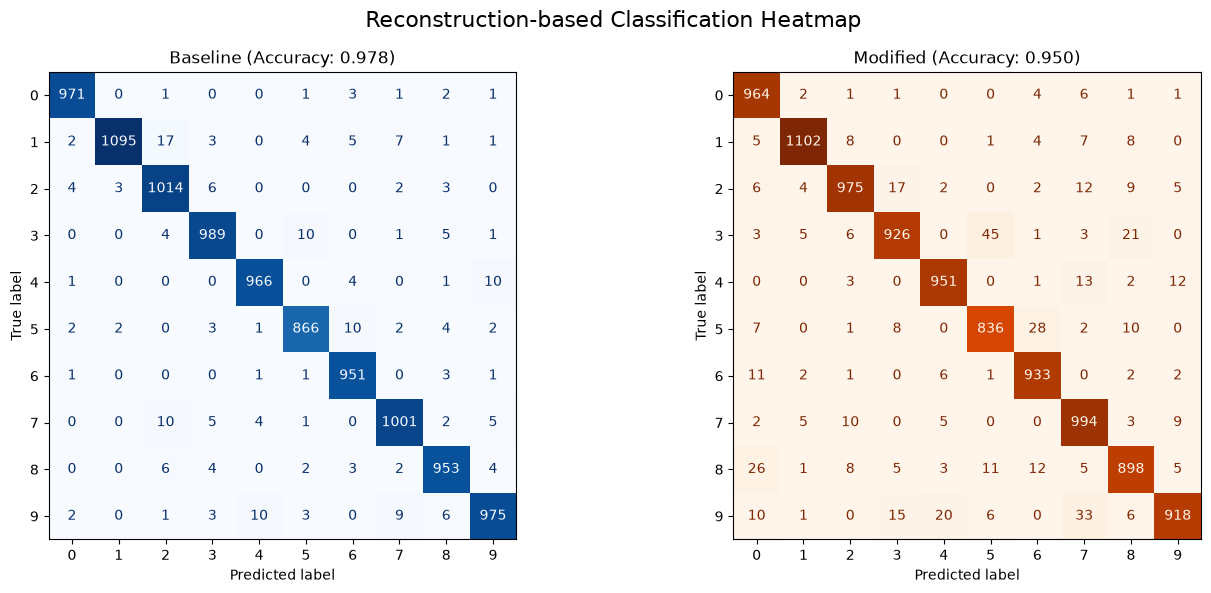

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Evaluate reconstruction-based classification
def plot_reconstruction_confusion_matrix(model, title):
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for x, labels in test_dataloader:
            x = x.to(device)
            labels = labels.to(device)

            errors = []

            for y_class in range(num_classes):
                y_onehot = F.one_hot(
                    torch.full(
                        (x.size(0),),
                        y_class,
                        device=device
                    ),
                    num_classes=num_classes
                ).float()

                mu, _ = model.encoder(x, y_onehot)
                x_hat = model.decode(mu, y_onehot)

                error = ((x - x_hat) ** 2).flatten(1).sum(1)
                errors.append(error)

            errors = torch.stack(errors, dim=1)
            preds = torch.argmin(errors, dim=1)

            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    cm = confusion_matrix(all_labels, all_preds)
    acc = cm.diagonal().sum() / float(cm.sum())

    return cm, acc

cm_base, acc_base = plot_reconstruction_confusion_matrix(
    base_vae,
    "Baseline"
)

cm_mod, acc_mod = plot_reconstruction_confusion_matrix(
    modified_vae,
    "Modified"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_base)
disp1.plot(cmap=plt.cm.Blues, ax=axes[0], colorbar=False)
axes[0].set_title(f"Baseline (Accuracy: {acc_base:.3f})")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_mod)
disp2.plot(cmap=plt.cm.Oranges, ax=axes[1], colorbar=False)
axes[1].set_title(f"Modified (Accuracy: {acc_mod:.3f})")

plt.suptitle("Reconstruction-based Classification Heatmap", fontsize=16)
plt.tight_layout()
plt.savefig(
    'assets/reconstruction_classification.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## Latent Space Analysis

To understand the internal representations learned by each model, we extract the latent variables (μ, σ) from the encoder for all test images and analyse their structure.

### 2D Histogram of Latent Means
Shows the density distribution of the first two latent dimensions. A well-structured latent space should show distinct clustering patterns.

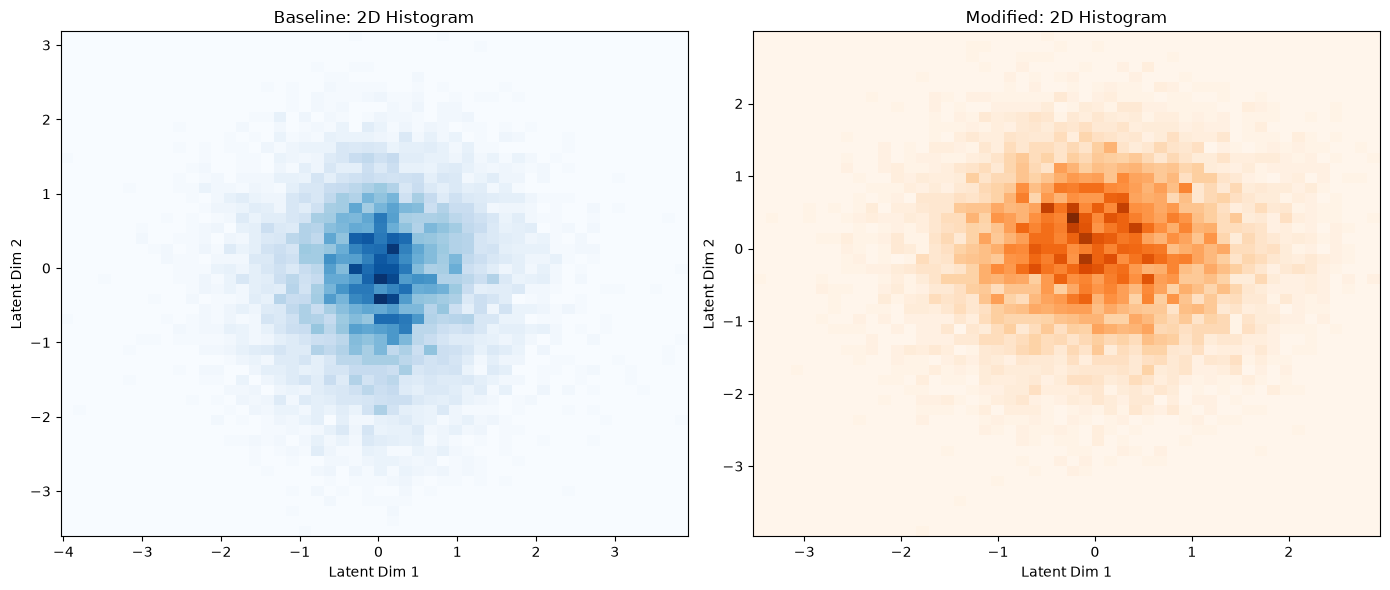

In [20]:
# Extract latent variables
def extract_latent_variables(model):
    latent_mu, latent_std, classes = [], [], []

    model.eval()
    with torch.no_grad():
        for x, labels in test_dataloader:
            x = x.to(device)
            labels = labels.to(device)
            cond = F.one_hot(labels, num_classes=num_classes).float()

            mu, logvar = model.encoder(x, cond)
            latent_mu.append(mu.cpu().numpy())
            latent_std.append(torch.exp(0.5 * logvar).cpu().numpy())
            classes.append(labels.cpu().numpy())

    return np.concatenate(latent_mu), np.concatenate(latent_std), np.concatenate(classes)

base_mu, base_std, test_classes = extract_latent_variables(base_vae)
mod_mu, mod_std, _ = extract_latent_variables(modified_vae)

# Plot 2D histograms of latent means
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist2d(base_mu[:, 0], base_mu[:, 1], bins=50, cmap='Blues')
axes[0].set_title('Baseline: 2D Histogram')
axes[0].set_xlabel('Latent Dim 1')
axes[0].set_ylabel('Latent Dim 2')

axes[1].hist2d(mod_mu[:, 0], mod_mu[:, 1], bins=50, cmap='Oranges')
axes[1].set_title('Modified: 2D Histogram')
axes[1].set_xlabel('Latent Dim 1')
axes[1].set_ylabel('Latent Dim 2')

plt.tight_layout()
plt.savefig('assets/latent_2d_hist.png', dpi=300, bbox_inches='tight')
plt.show()

### KDE Distributions and Standard Deviations

**Top row**: Kernel Density Estimates of each latent dimension's mean values, comparing baseline vs. modified.  
**Bottom row**: Distribution of learned standard deviations — these control how much the model "spreads" each encoding.  

A model with tighter σ values tends to produce less diverse but potentially sharper outputs.

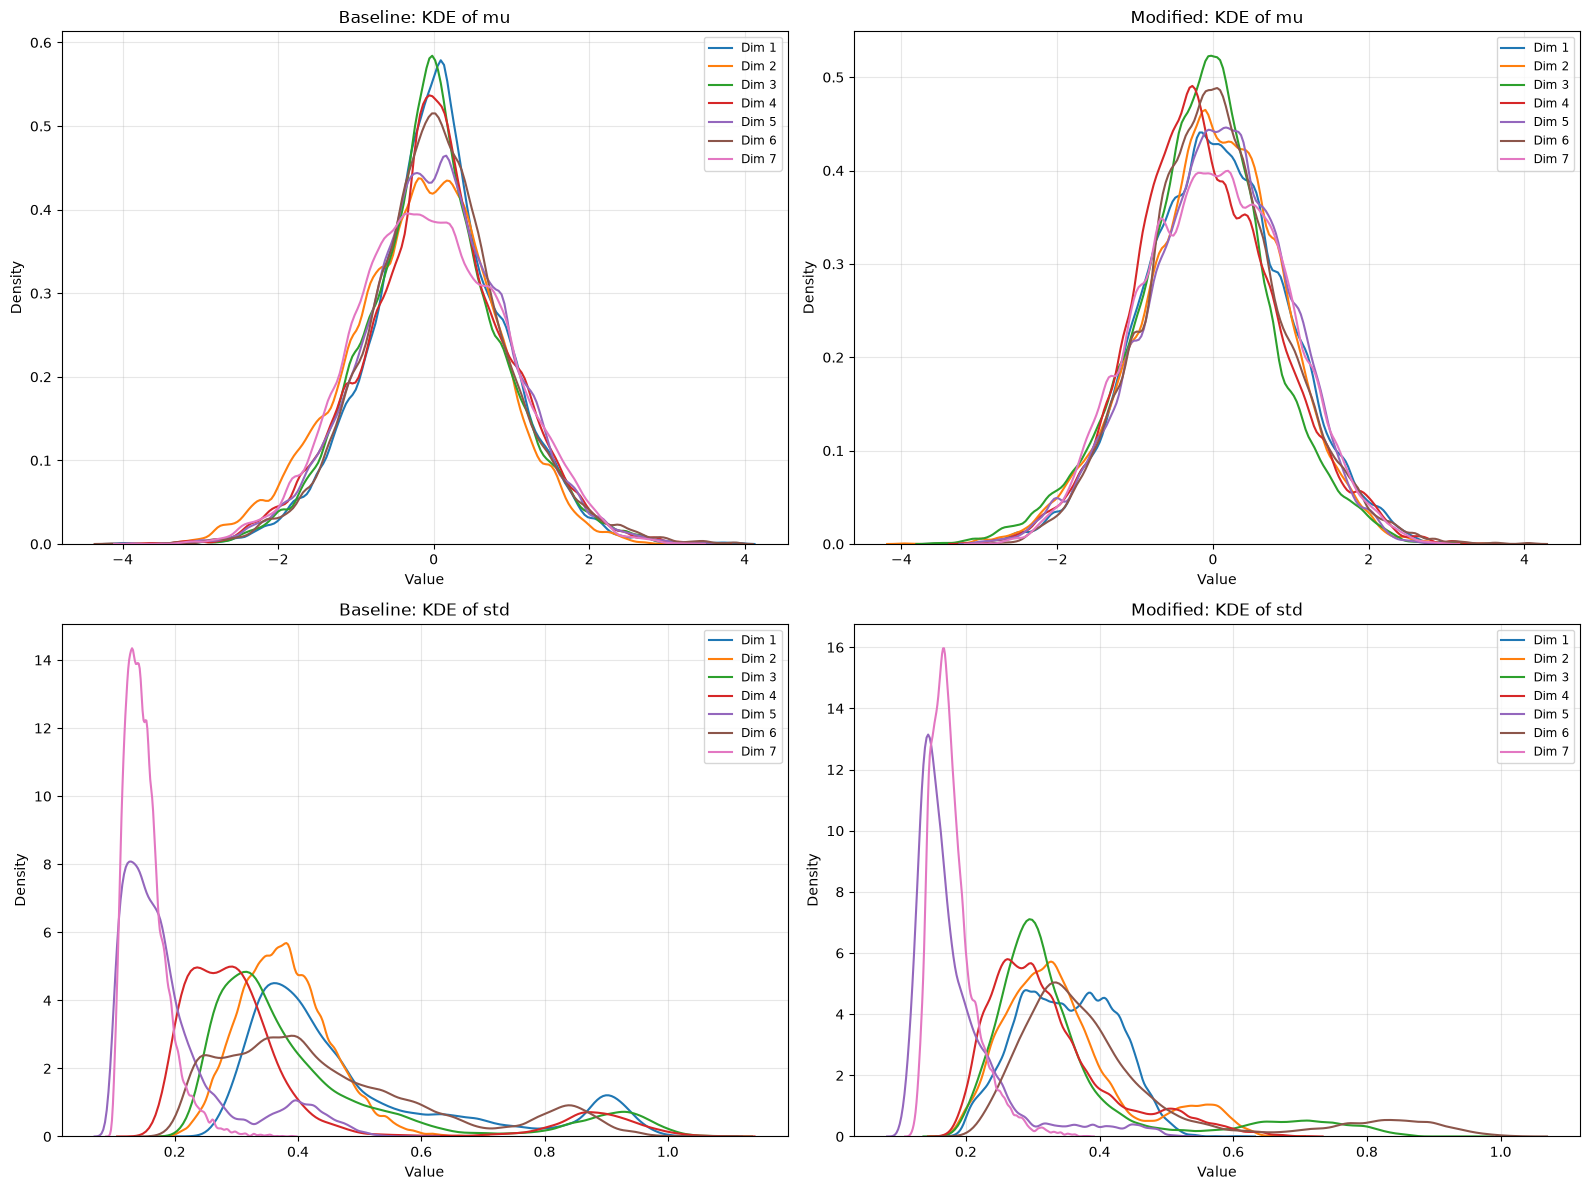

In [21]:
import seaborn as sns

# Plot KDE distributions of latent means and standard deviations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for i in range(z_dim):
    sns.kdeplot(base_mu[:, i], ax=axes[0, 0], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)
    sns.kdeplot(mod_mu[:, i], ax=axes[0, 1], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)

axes[0, 0].set_title('Baseline: KDE of mu')
axes[0, 1].set_title('Modified: KDE of mu')

for i in range(z_dim):
    sns.kdeplot(base_std[:, i], ax=axes[1, 0], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)
    sns.kdeplot(mod_std[:, i], ax=axes[1, 1], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)

axes[1, 0].set_title('Baseline: KDE of std')
axes[1, 1].set_title('Modified: KDE of std')

for ax in axes.flat:
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize='small', loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('assets/latent_kde_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

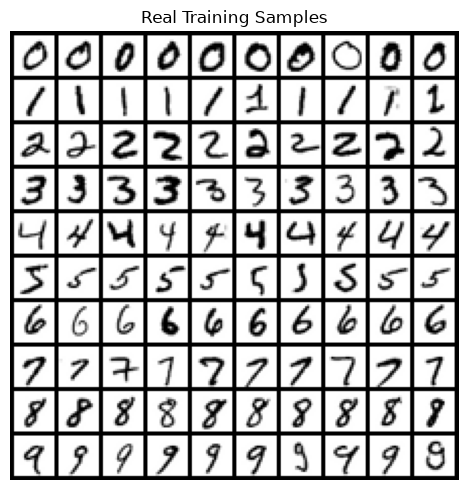

In [22]:
# Select 10 training samples from each digit class
train_images = data_custom['train_images']
train_labels = data_custom['train_labels']

samples = []

for digit in range(num_classes):
    indices = torch.where(train_labels == digit)[0][:10]
    samples.append(train_images[indices])

train_samples = torch.cat(samples, dim=0)

# Display training samples in a 10 x 10 grid
train_grid = make_grid(train_samples, nrow=10, padding=2)

plt.figure(figsize=(5, 5))
plt.imshow(train_grid.permute(1, 2, 0).squeeze(), cmap='gray')
plt.title('Real Training Samples')
plt.axis('off')
plt.tight_layout()
plt.savefig('assets/real_training_samples.png', dpi=300, bbox_inches='tight')
plt.show()

## Discussion

The results provide partial support for the hypothesis that adding a discriminator loss improves the sharpness of cVAE-generated images. The modified cVAE achieved a mean Laplacian variance of **0.185**, almost twice the baseline value of **0.093**, indicating stronger local intensity changes around image edges. However, the modified model also showed greater variation in Laplacian variance across generated samples, suggesting that the effect was not consistent across all images. Qualitative inspection supports a cautious interpretation of this result: some modified samples contain more irregular or distorted edges, which can also increase Laplacian variance without necessarily representing an improvement in perceptual sharpness. Therefore, the quantitative result supports higher **measured sharpness**, but not uniformly sharper-looking images.

The other evaluation metrics reveal a more complex effect on generation quality. The modified model showed lower generated-digit recognisability, at **92.9%** compared with **98.9%** for the baseline, and a higher FCD, at **5.35** compared with **2.79**. Importantly, lower classifier recognisability does not necessarily mean that the modified model generated the wrong conditioning class. The standalone classifier measures whether a generated image can be clearly recognised as its intended class, whereas the adversarial objective encourages generated images to resemble examples from the real training distribution. Inspection of the training data shows substantial handwriting variation, including irregular and visually ambiguous digit shapes. Consequently, a generated digit may reflect variation present within its conditioning class while still being interpreted as another digit by the standalone classifier. However, the higher FCD also indicates that the modified samples were not closer to the real-data distribution in the classifier feature space. Therefore, the discriminator objective should not be interpreted as having successfully improved realism solely because it was designed to distinguish real and generated images.

These findings demonstrate that **sharpness, recognisability, distribution similarity, and perceptual quality are related but distinct properties**. A generated image can contain stronger local edge changes while having an ambiguous digit shape, and an easily classified image is not necessarily a better representation of natural handwriting variation. The results therefore do not support a single conclusion that the discriminator made the generated images generally better or worse. Instead, the clearest effect is higher measured edge sharpness, accompanied by greater sharpness variability, lower classifier recognisability, and greater feature-distribution distance.

The latent-space analysis provides further context. The 2D histogram shows a difference in the joint structure of the first two latent means: the baseline distribution is more vertically elongated, whereas the modified distribution is more rounded around the centre. In contrast, the KDE plots show broadly similar marginal distributions of latent means and standard deviations between the two models, with only minor dimension-specific differences. This suggests that the adversarial objective affected relationships within the latent representation without substantially changing the overall marginal latent distributions. These observations should not be interpreted as evidence that either latent representation is inherently better, but they indicate that the discriminator can influence how latent information is organised even when the individual latent distributions remain similar.

One limitation is the relative weighting of the adversarial objective. The modified model used

$$
\mathcal{L}_{modified}=\mathcal{L}_{VAE}+\mathcal{L}_{G},
$$

equivalent to an adversarial weight of $\alpha=1$. Since only this weighting was evaluated, it cannot be concluded that the observed changes were caused by excessive adversarial influence. Nevertheless, the combination of higher measured sharpness with lower recognisability suggests that the balance between the reconstruction, KL, and adversarial objectives may influence the trade-off between these properties. A useful extension would therefore be

$$
\mathcal{L}_{modified}=\mathcal{L}_{VAE}+\alpha\mathcal{L}_{G},
$$

with values such as $\alpha \in \{0.1,0.25,0.5,1.0\}$ evaluated under the same experimental procedure. The objective would be to determine whether the sharpening effect can be retained while improving recognisability and feature-distribution similarity.

Overall, the hypothesis is supported specifically with respect to measured sharpness. The modified cVAE produced higher Laplacian variance, although this effect varied more across generated samples and some irregular edges may have contributed to the increase. Its lower digit recognisability may indicate that the adversarial objective encouraged the model to reproduce more specific handwriting variations present in real images, rather than consistently generating generalised and easily recognisable digit patterns. This interpretation is consistent with the irregular and ambiguous digit shapes observed in the training data, although recognisability alone cannot establish that the modified samples are more realistic. Therefore, the results demonstrate an improvement in measured sharpness while suggesting that the discriminator loss may also change the type of handwriting variation captured by the model.

## Conclusion

The discriminator loss resulted in higher measured sharpness, while the baseline cVAE achieved higher digit recognisability and lower FCD in the classifier feature space. Overall, the results support the hypothesis with respect to measured sharpness, but also suggest that the discriminator loss may change the handwriting variations captured by the model. Future work could evaluate different adversarial loss weights to examine whether higher sharpness can be retained while improving recognisability and FCD.